## 1. Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

## 2. Load the dataset



In [78]:
df = pd.read_csv("Bangladesh_Indoor_Air_Quality_Cleaned.csv")

# df = df.head().copy()

df

,Timestamp,Indoor Temperature (°C),Indoor Humidity (%),CO2 (ppm),CO (ppm),NO2 (ppb),PM2.5 (µg/m³),PM10 (µg/m³),TVOC (ppb),Outdoor Temperature (°C),Outdoor Humidity (%),Rainfall (mm),Occupancy (people),Number of Rooms,Ventilation Type,Cooking Fuel,Cooking Frequency (per day),Household Size,Nearby Traffic,Floor Level,Time of Day,Season
0,2024-01-01 06:00:00,29.99,58.22,1021.90,0.00,34.11,5.00,10.00,259.96,32.95,71.15,0,3,3,fan,gas,2,4,medium,top,morning,winter
1,2024-01-01 06:15:00,28.72,61.95,999.16,3.89,38.88,18.90,26.60,479.22,29.84,80.98,0,2,2,exhaust fan,gas,4,2,medium,1st,morning,winter
2,2024-01-01 06:30:00,30.30,59.03,572.22,0.53,48.55,28.26,45.87,256.48,29.83,88.73,0,1,2,exhaust fan,gas,4,1,low,2nd,morning,winter
3,2024-01-01 06:45:00,32.05,66.10,1102.85,2.09,38.13,42.99,52.90,177.24,30.94,71.89,2,3,4,fan,gas,3,3,medium,1st,morning,winter
4,2024-01-01 07:00:00,28.53,76.97,400.00,1.50,28.02,60.48,89.42,616.98,32.64,85.76,0,1,4,fan,electric,2,3,low,2nd,morning,winter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2024-04-14 08:45:00,31.60,68.88,697.95,0.00,19.66,62.39,110.72,398.49,30.09,62.88,2,1,2,fan,gas,2,1,low,1st,morning,summer
9996,2024-04-14 09:00:00,25.00,78.77,1405.61,0.00,28.47,45.30,75.03,257.57,35.24,74.53,0,5,3,fan,induction,1,7,medium,1st,morning,summer
9997,2024-04-14 09:15:00,27.59,68.78,724.52,3.57,20.82,52.33,88.72,100.11,32.52,33.75,0,1,5,exhaust fan,gas,4,1,medium,top,morning,summer
9998,2024-04-14 09:30:00,29.99,82.14,400.00,3.58,23.21,56.29,78.48,302.98,32.99,80.48,0,1,2,fan,gas,1,1,low,top,morning,summer


## 3. Check the dataset size

In [79]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 22


## 4. Check the required variables

In [5]:
required_columns = [
    "Indoor Temperature (°C)",
    "Indoor Humidity (%)",
    "CO2 (ppm)",
    "CO (ppm)",
    "NO2 (ppb)",
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "TVOC (ppb)",
    "Outdoor Temperature (°C)",
    "Outdoor Humidity (%)",
    "Rainfall (mm)",
    "Occupancy (people)",
    "Number of Rooms",
    "Cooking Frequency (per day)",
    "Household Size",
    "Ventilation Type",
    "Cooking Fuel",
    "Nearby Traffic",
    "Floor Level",
    "Time of Day",
    "Season"
]

missing_columns = [column for column in required_columns if column not in df.columns]

if missing_columns:
    raise KeyError(f"These columns are missing: {missing_columns}")

print("All required variables are available.")

All required variables are available.


## 5. Convert the numerical variables to numbers

In [6]:
numerical_columns = [
    "Indoor Temperature (°C)",
    "Indoor Humidity (%)",
    "CO2 (ppm)",
    "CO (ppm)",
    "NO2 (ppb)",
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "TVOC (ppb)",
    "Outdoor Temperature (°C)",
    "Outdoor Humidity (%)",
    "Rainfall (mm)",
    "Occupancy (people)",
    "Number of Rooms",
    "Cooking Frequency (per day)",
    "Household Size"
]

for column in numerical_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Numerical variables are ready for analysis.")

Numerical variables are ready for analysis.


# Part A: Central Tendency and Dispersion

This part calculates the mean, median, mode, variance, standard deviation, Q1, Q3, and IQR for the 15 numerical variables.

## 6. Select the numerical data

In [7]:
central_data = df[numerical_columns].copy()
central_data

,Indoor Temperature (°C),Indoor Humidity (%),CO2 (ppm),CO (ppm),NO2 (ppb),PM2.5 (µg/m³),PM10 (µg/m³),TVOC (ppb),Outdoor Temperature (°C),Outdoor Humidity (%),Rainfall (mm),Occupancy (people),Number of Rooms,Cooking Frequency (per day),Household Size
0,29.99,58.22,1021.90,0.00,34.11,5.00,10.00,259.96,32.95,71.15,0,3,3,2,4
1,28.72,61.95,999.16,3.89,38.88,18.90,26.60,479.22,29.84,80.98,0,2,2,4,2
2,30.30,59.03,572.22,0.53,48.55,28.26,45.87,256.48,29.83,88.73,0,1,2,4,1
3,32.05,66.10,1102.85,2.09,38.13,42.99,52.90,177.24,30.94,71.89,2,3,4,3,3
4,28.53,76.97,400.00,1.50,28.02,60.48,89.42,616.98,32.64,85.76,0,1,4,2,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,31.60,68.88,697.95,0.00,19.66,62.39,110.72,398.49,30.09,62.88,2,1,2,2,1
9996,25.00,78.77,1405.61,0.00,28.47,45.30,75.03,257.57,35.24,74.53,0,5,3,1,7
9997,27.59,68.78,724.52,3.57,20.82,52.33,88.72,100.11,32.52,33.75,0,1,5,4,1
9998,29.99,82.14,400.00,3.58,23.21,56.29,78.48,302.98,32.99,80.48,0,1,2,1,1


## 7. Calculate the mean

In [8]:
mean_values = central_data.mean()
mean_values

Indoor Temperature (°C)        29.00
Indoor Humidity (%)            65.11
CO2 (ppm)                     907.05
CO (ppm)                        1.39
NO2 (ppb)                      25.42
PM2.5 (µg/m³)                  40.19
PM10 (µg/m³)                   60.42
TVOC (ppb)                    299.88
Outdoor Temperature (°C)       29.98
Outdoor Humidity (%)           70.06
Rainfall (mm)                   1.26
Occupancy (people)              2.28
Number of Rooms                 3.17
Cooking Frequency (per day)     2.40
Household Size                  2.78
dtype: float64

## 8. Calculate the median

In [9]:
median_values = central_data.median()
median_values

Indoor Temperature (°C)        28.99
Indoor Humidity (%)            65.16
CO2 (ppm)                     897.98
CO (ppm)                        1.22
NO2 (ppb)                      25.27
PM2.5 (µg/m³)                  39.79
PM10 (µg/m³)                   59.09
TVOC (ppb)                    299.70
Outdoor Temperature (°C)       29.96
Outdoor Humidity (%)           70.15
Rainfall (mm)                   0.00
Occupancy (people)              2.00
Number of Rooms                 3.00
Cooking Frequency (per day)     2.00
Household Size                  3.00
dtype: float64

## 9. Calculate the mode

In [10]:
mode_values = central_data.mode().iloc[0]
mode_values

Indoor Temperature (°C)        21.16
Indoor Humidity (%)            90.00
CO2 (ppm)                     400.00
CO (ppm)                        0.00
NO2 (ppb)                       5.00
PM2.5 (µg/m³)                   5.00
PM10 (µg/m³)                   10.00
TVOC (ppb)                     50.00
Outdoor Temperature (°C)       20.00
Outdoor Humidity (%)          100.00
Rainfall (mm)                   0.00
Occupancy (people)              1.00
Number of Rooms                 3.00
Cooking Frequency (per day)     2.00
Household Size                  2.00
Name: 0, dtype: float64

## 10. Calculate the variance

In [11]:
variance_values = central_data.var()
variance_values

Indoor Temperature (°C)            4.03
Indoor Humidity (%)               98.93
CO2 (ppm)                     105892.65
CO (ppm)                           1.53
NO2 (ppb)                        132.71
PM2.5 (µg/m³)                    374.82
PM10 (µg/m³)                     888.39
TVOC (ppb)                     13926.33
Outdoor Temperature (°C)           9.00
Outdoor Humidity (%)             216.34
Rainfall (mm)                     16.79
Occupancy (people)                 1.82
Number of Rooms                    0.84
Cooking Frequency (per day)        0.64
Household Size                     2.25
dtype: float64

## 11. Calculate the standard deviation

In [12]:
standard_deviation = central_data.std()
standard_deviation

Indoor Temperature (°C)         2.01
Indoor Humidity (%)             9.95
CO2 (ppm)                     325.41
CO (ppm)                        1.24
NO2 (ppb)                      11.52
PM2.5 (µg/m³)                  19.36
PM10 (µg/m³)                   29.81
TVOC (ppb)                    118.01
Outdoor Temperature (°C)        3.00
Outdoor Humidity (%)           14.71
Rainfall (mm)                   4.10
Occupancy (people)              1.35
Number of Rooms                 0.92
Cooking Frequency (per day)     0.80
Household Size                  1.50
dtype: float64

## 12. Calculate Q1 and Q3

In [13]:
q1_all = central_data.quantile(0.25)
q3_all = central_data.quantile(0.75)

pd.DataFrame({
    "Q1": q1_all,
    "Q3": q3_all
})

,Q1,Q3
Indoor Temperature (°C),27.65,30.34
Indoor Humidity (%),58.38,71.94
CO2 (ppm),654.95,1132.36
CO (ppm),0.18,2.22
NO2 (ppb),17.02,33.29
PM2.5 (µg/m³),26.11,53.58
PM10 (µg/m³),38.38,80.27
TVOC (ppb),219.80,380.25
Outdoor Temperature (°C),27.95,32.01
Outdoor Humidity (%),60.30,80.15


## 13. Calculate the IQR

**IQR = Q3 − Q1**

In [14]:
iqr_all = q3_all - q1_all
iqr_all

Indoor Temperature (°C)         2.69
Indoor Humidity (%)            13.56
CO2 (ppm)                     477.42
CO (ppm)                        2.04
NO2 (ppb)                      16.28
PM2.5 (µg/m³)                  27.47
PM10 (µg/m³)                   41.89
TVOC (ppb)                    160.44
Outdoor Temperature (°C)        4.06
Outdoor Humidity (%)           19.85
Rainfall (mm)                   0.00
Occupancy (people)              2.00
Number of Rooms                 1.00
Cooking Frequency (per day)     1.00
Household Size                  2.00
dtype: float64

## 14. Create the descriptive-statistics table

In [15]:
descriptive_summary = pd.DataFrame({
    "Mean": mean_values,
    "Median": median_values,
    "Mode": mode_values,
    "Variance": variance_values,
    "Standard Deviation": standard_deviation,
    "Q1": q1_all,
    "Q3": q3_all,
    "IQR": iqr_all
})

descriptive_summary

,Mean,Median,Mode,Variance,Standard Deviation,Q1,Q3,IQR
Indoor Temperature (°C),29.00,28.99,21.16,4.03,2.01,27.65,30.34,2.69
Indoor Humidity (%),65.11,65.16,90.00,98.93,9.95,58.38,71.94,13.56
CO2 (ppm),907.05,897.98,400.00,105892.65,325.41,654.95,1132.36,477.42
CO (ppm),1.39,1.22,0.00,1.53,1.24,0.18,2.22,2.04
NO2 (ppb),25.42,25.27,5.00,132.71,11.52,17.02,33.29,16.28
PM2.5 (µg/m³),40.19,39.79,5.00,374.82,19.36,26.11,53.58,27.47
PM10 (µg/m³),60.42,59.09,10.00,888.39,29.81,38.38,80.27,41.89
TVOC (ppb),299.88,299.70,50.00,13926.33,118.01,219.80,380.25,160.44
Outdoor Temperature (°C),29.98,29.96,20.00,9.00,3.00,27.95,32.01,4.06
Outdoor Humidity (%),70.06,70.15,100.00,216.34,14.71,60.30,80.15,19.85


## 15. Compare the mean and median

In [16]:
descriptive_summary["Mean-Median Difference"] = (descriptive_summary["Mean"] - descriptive_summary["Median"]).abs()

descriptive_summary[["Mean","Median","Mean-Median Difference"]]

,Mean,Median,Mean-Median Difference
Indoor Temperature (°C),29.00,28.99,0.00
Indoor Humidity (%),65.11,65.16,0.04
CO2 (ppm),907.05,897.98,9.07
CO (ppm),1.39,1.22,0.17
NO2 (ppb),25.42,25.27,0.15
PM2.5 (µg/m³),40.19,39.79,0.39
PM10 (µg/m³),60.42,59.09,1.33
TVOC (ppb),299.88,299.70,0.19
Outdoor Temperature (°C),29.98,29.96,0.02
Outdoor Humidity (%),70.06,70.15,0.09


## 16. Calculate relative variability

The coefficient of variation compares the standard deviation with the mean.

A higher percentage means greater relative variability.

In [17]:
descriptive_summary["Coefficient of Variation (%)"] = (descriptive_summary["Standard Deviation"]
    / descriptive_summary["Mean"].abs()) * 100

descriptive_summary[["Mean","Standard Deviation","Coefficient of Variation (%)"]].sort_values("Coefficient of Variation (%)", ascending=False)

,Mean,Standard Deviation,Coefficient of Variation (%)
Rainfall (mm),1.26,4.10,325.41
CO (ppm),1.39,1.24,89.31
Occupancy (people),2.28,1.35,59.23
Household Size,2.78,1.50,53.96
PM10 (µg/m³),60.42,29.81,49.33
PM2.5 (µg/m³),40.19,19.36,48.18
NO2 (ppb),25.42,11.52,45.32
TVOC (ppb),299.88,118.01,39.35
CO2 (ppm),907.05,325.41,35.88
Cooking Frequency (per day),2.40,0.80,33.42


## 17. Identify high and low variability

In [18]:
highest_cv = descriptive_summary["Coefficient of Variation (%)"].idxmax()
lowest_cv = descriptive_summary["Coefficient of Variation (%)"].idxmin()

print("Highest relative variability:", highest_cv)
print("Lowest relative variability:", lowest_cv)

Highest relative variability: Rainfall (mm)
Lowest relative variability: Indoor Temperature (°C)


## 18. Short interpretation

- A larger mean–median difference may indicate a skewed distribution.
- A higher coefficient of variation indicates greater relative variability.
- The mode is most useful for discrete variables such as occupancy, rooms, cooking frequency, and household size.
- Raw standard deviations should not be compared directly when variables use different units.

## 19. Display the final descriptive table

In [19]:
descriptive_summary.round(2)

,Mean,Median,Mode,Variance,Standard Deviation,Q1,Q3,IQR,Mean-Median Difference,Coefficient of Variation (%)
Indoor Temperature (°C),29.00,28.99,21.16,4.03,2.01,27.65,30.34,2.69,0.00,6.92
Indoor Humidity (%),65.11,65.16,90.00,98.93,9.95,58.38,71.94,13.56,0.04,15.28
CO2 (ppm),907.05,897.98,400.00,105892.65,325.41,654.95,1132.36,477.42,9.07,35.88
CO (ppm),1.39,1.22,0.00,1.53,1.24,0.18,2.22,2.04,0.17,89.31
NO2 (ppb),25.42,25.27,5.00,132.71,11.52,17.02,33.29,16.28,0.15,45.32
PM2.5 (µg/m³),40.19,39.79,5.00,374.82,19.36,26.11,53.58,27.47,0.39,48.18
PM10 (µg/m³),60.42,59.09,10.00,888.39,29.81,38.38,80.27,41.89,1.33,49.33
TVOC (ppb),299.88,299.70,50.00,13926.33,118.01,219.80,380.25,160.44,0.19,39.35
Outdoor Temperature (°C),29.98,29.96,20.00,9.00,3.00,27.95,32.01,4.06,0.02,10.01
Outdoor Humidity (%),70.06,70.15,100.00,216.34,14.71,60.30,80.15,19.85,0.09,20.99


# Part B: Distribution Shape and Outlier Analysis

This part uses the 10 required air-quality and weather variables.

## 20. Select and rename the 10 required variables

In [20]:
distribution_columns = {
    "CO2 (ppm)": "CO₂",
    "PM2.5 (µg/m³)": "PM2.5",
    "PM10 (µg/m³)": "PM10",
    "CO (ppm)": "CO",
    "NO2 (ppb)": "NO₂",
    "TVOC (ppb)": "TVOC",
    "Indoor Temperature (°C)": "Indoor Temperature",
    "Indoor Humidity (%)": "Indoor Humidity",
    "Outdoor Temperature (°C)": "Outdoor Temperature",
    "Rainfall (mm)": "Rainfall"
}

data = df[list(distribution_columns.keys())].rename(
    columns=distribution_columns
)

data

,CO₂,PM2.5,PM10,CO,NO₂,TVOC,Indoor Temperature,Indoor Humidity,Outdoor Temperature,Rainfall
0,1021.90,5.00,10.00,0.00,34.11,259.96,29.99,58.22,32.95,0
1,999.16,18.90,26.60,3.89,38.88,479.22,28.72,61.95,29.84,0
2,572.22,28.26,45.87,0.53,48.55,256.48,30.30,59.03,29.83,0
3,1102.85,42.99,52.90,2.09,38.13,177.24,32.05,66.10,30.94,2
4,400.00,60.48,89.42,1.50,28.02,616.98,28.53,76.97,32.64,0
...,...,...,...,...,...,...,...,...,...,...
9995,697.95,62.39,110.72,0.00,19.66,398.49,31.60,68.88,30.09,2
9996,1405.61,45.30,75.03,0.00,28.47,257.57,25.00,78.77,35.24,0
9997,724.52,52.33,88.72,3.57,20.82,100.11,27.59,68.78,32.52,0
9998,400.00,56.29,78.48,3.58,23.21,302.98,29.99,82.14,32.99,0


## 21. Check the selected data

In [21]:
data.shape

(10000, 10)

## 22. Calculate skewness

In [22]:
skewness = data.skew()
skewness

CO₂                    0.31
PM2.5                  0.20
PM10                   0.36
CO                     0.72
NO₂                    0.21
TVOC                   0.10
Indoor Temperature     0.00
Indoor Humidity       -0.05
Outdoor Temperature    0.03
Rainfall               3.62
dtype: float64

## 23. Classify the distribution shape

- **−0.5 to +0.5:** Approximately symmetric
- **Greater than +0.5:** Right-skewed
- **Less than −0.5:** Left-skewed

In [23]:
def classify_skew(value):
    if -0.5 <= value <= 0.5:
        return "Approximately symmetric"
    elif value > 0.5:
        return "Right-skewed"
    else:
        return "Left-skewed"

distribution_shape = skewness.apply(classify_skew)
distribution_shape

CO₂                    Approximately symmetric
PM2.5                  Approximately symmetric
PM10                   Approximately symmetric
CO                                Right-skewed
NO₂                    Approximately symmetric
TVOC                   Approximately symmetric
Indoor Temperature     Approximately symmetric
Indoor Humidity        Approximately symmetric
Outdoor Temperature    Approximately symmetric
Rainfall                          Right-skewed
dtype: str

## 24. Calculate kurtosis

In [24]:
kurtosis = data.kurt()
kurtosis

CO₂                   -0.43
PM2.5                 -0.34
PM10                  -0.14
CO                    -0.13
NO₂                   -0.37
TVOC                  -0.20
Indoor Temperature     0.03
Indoor Humidity       -0.07
Outdoor Temperature   -0.04
Rainfall              12.26
dtype: float64

## 25. Identify heavy-tailed distributions

Pandas reports excess kurtosis. A value greater than zero is classified as heavy-tailed.

In [25]:
heavy_tailed = kurtosis.apply(
    lambda value: "Yes" if value > 0 else "No"
)

heavy_tailed

CO₂                     No
PM2.5                   No
PM10                    No
CO                      No
NO₂                     No
TVOC                    No
Indoor Temperature     Yes
Indoor Humidity         No
Outdoor Temperature     No
Rainfall               Yes
dtype: str

## 26. Calculate Q1 and Q3

In [26]:
q1 = data.quantile(0.25)
q3 = data.quantile(0.75)

pd.DataFrame({
    "Q1": q1,
    "Q3": q3
})

,Q1,Q3
CO₂,654.95,1132.36
PM2.5,26.11,53.58
PM10,38.38,80.27
CO,0.18,2.22
NO₂,17.02,33.29
TVOC,219.80,380.25
Indoor Temperature,27.65,30.34
Indoor Humidity,58.38,71.94
Outdoor Temperature,27.95,32.01
Rainfall,0.00,0.00


## 27. Calculate the IQR

**IQR = Q3 − Q1**

In [27]:
iqr = q3 - q1
iqr

CO₂                   477.42
PM2.5                  27.47
PM10                   41.89
CO                      2.04
NO₂                    16.28
TVOC                  160.44
Indoor Temperature      2.69
Indoor Humidity        13.56
Outdoor Temperature     4.06
Rainfall                0.00
dtype: float64

## 28. Calculate the lower and upper outlier limits

In [28]:
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

pd.DataFrame({
    "Lower Limit": lower_limit,
    "Upper Limit": upper_limit
})

,Lower Limit,Upper Limit
CO₂,-61.18,1848.49
PM2.5,-15.10,94.79
PM10,-24.44,143.10
CO,-2.87,5.28
NO₂,-7.40,57.71
TVOC,-20.86,620.91
Indoor Temperature,23.62,34.37
Indoor Humidity,38.04,92.28
Outdoor Temperature,21.85,38.11
Rainfall,0.00,0.00


## 29. Identify possible outliers

In [29]:
outliers = (data < lower_limit) | (data > upper_limit)
outliers.head()

,CO₂,PM2.5,PM10,CO,NO₂,TVOC,Indoor Temperature,Indoor Humidity,Outdoor Temperature,Rainfall
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,True
4,False,False,False,False,False,False,False,False,False,False


## 30. Count the possible outliers

In [30]:
outlier_count = outliers.sum()
outlier_count

CO₂                      25
PM2.5                    28
PM10                     59
CO                       28
NO₂                      32
TVOC                     33
Indoor Temperature       83
Indoor Humidity          48
Outdoor Temperature      65
Rainfall               1525
dtype: int64

## 31. Calculate the outlier percentage

In [31]:
outlier_percentage = outlier_count / data.count() * 100
outlier_percentage

CO₂                    0.25
PM2.5                  0.28
PM10                   0.59
CO                     0.28
NO₂                    0.32
TVOC                   0.33
Indoor Temperature     0.83
Indoor Humidity        0.48
Outdoor Temperature    0.65
Rainfall              15.25
dtype: float64

## 32. Create the distribution-summary table

In [32]:
distribution_summary = pd.DataFrame({
    "Skewness": skewness,
    "Distribution Shape": distribution_shape,
    "Kurtosis": kurtosis,
    "Heavy-tailed": heavy_tailed,
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Lower Limit": lower_limit,
    "Upper Limit": upper_limit,
    "Number of Outliers": outlier_count,
    "Percentage of Outliers": outlier_percentage
})

distribution_summary.round(2)

,Skewness,Distribution Shape,Kurtosis,Heavy-tailed,Q1,Q3,IQR,Lower Limit,Upper Limit,Number of Outliers,Percentage of Outliers
CO₂,0.31,Approximately symmetric,-0.43,No,654.95,1132.36,477.42,-61.18,1848.49,25,0.25
PM2.5,0.20,Approximately symmetric,-0.34,No,26.11,53.58,27.47,-15.10,94.79,28,0.28
PM10,0.36,Approximately symmetric,-0.14,No,38.38,80.27,41.89,-24.44,143.10,59,0.59
CO,0.72,Right-skewed,-0.13,No,0.18,2.22,2.04,-2.87,5.28,28,0.28
NO₂,0.21,Approximately symmetric,-0.37,No,17.02,33.29,16.28,-7.40,57.71,32,0.32
TVOC,0.10,Approximately symmetric,-0.20,No,219.80,380.25,160.44,-20.86,620.91,33,0.33
Indoor Temperature,0.00,Approximately symmetric,0.03,Yes,27.65,30.34,2.69,23.62,34.37,83,0.83
Indoor Humidity,-0.05,Approximately symmetric,-0.07,No,58.38,71.94,13.56,38.04,92.28,48,0.48
Outdoor Temperature,0.03,Approximately symmetric,-0.04,No,27.95,32.01,4.06,21.85,38.11,65,0.65
Rainfall,3.62,Right-skewed,12.26,Yes,0.00,0.00,0.00,0.00,0.00,1525,15.25


## 33. Display the main results

In [33]:
print("Most highly skewed variable:", skewness.abs().idxmax())
print("Approximately symmetric variables:",
      distribution_shape[distribution_shape == "Approximately symmetric"].index.tolist())
print("Right-skewed variables:",
      distribution_shape[distribution_shape == "Right-skewed"].index.tolist())
print("Left-skewed variables:",
      distribution_shape[distribution_shape == "Left-skewed"].index.tolist())
print("Heavy-tailed variables:",
      heavy_tailed[heavy_tailed == "Yes"].index.tolist())
print("Highest number of outliers:", outlier_count.idxmax())
print("Highest outlier percentage:", outlier_percentage.idxmax())
print("Largest IQR:", iqr.idxmax())

Most highly skewed variable: Rainfall
Approximately symmetric variables: ['CO₂', 'PM2.5', 'PM10', 'NO₂', 'TVOC', 'Indoor Temperature', 'Indoor Humidity', 'Outdoor Temperature']
Right-skewed variables: ['CO', 'Rainfall']
Left-skewed variables: []
Heavy-tailed variables: ['Indoor Temperature', 'Rainfall']
Highest number of outliers: Rainfall
Highest outlier percentage: Rainfall
Largest IQR: CO₂


## 34. Graphs and short interpretations

For every variable, the notebook shows:

- Histogram
- Density plot
- Boxplot
- A short interpretation generated from the calculated results

### CO₂

#### Histogram

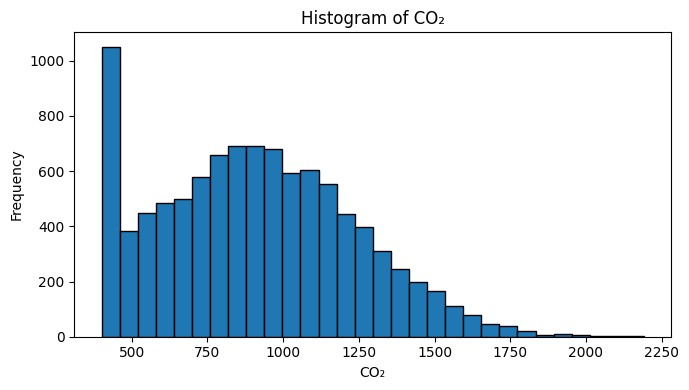

In [34]:
plt.figure(figsize=(7, 4))
plt.hist(data["CO₂"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of CO₂")
plt.xlabel("CO₂")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

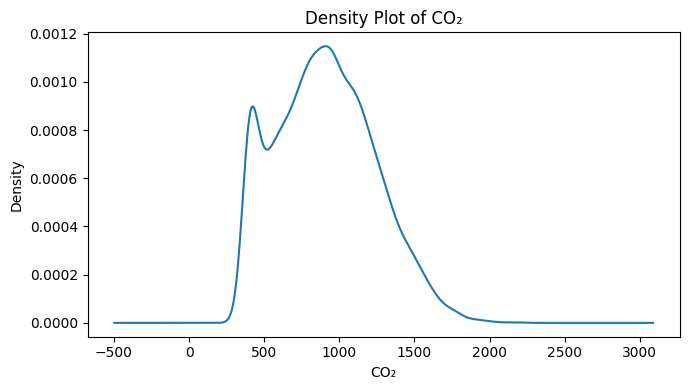

In [35]:
plt.figure(figsize=(7, 4))
data["CO₂"].dropna().plot(kind="density")
plt.title("Density Plot of CO₂")
plt.xlabel("CO₂")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

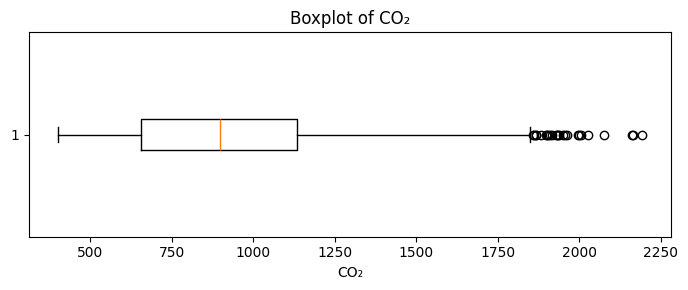

In [36]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["CO₂"].dropna(), vert=False)
plt.title("Boxplot of CO₂")
plt.xlabel("CO₂")
plt.tight_layout()
plt.show()

#### Short interpretation

In [37]:
# show_interpretation("CO₂")

### PM2.5

#### Histogram

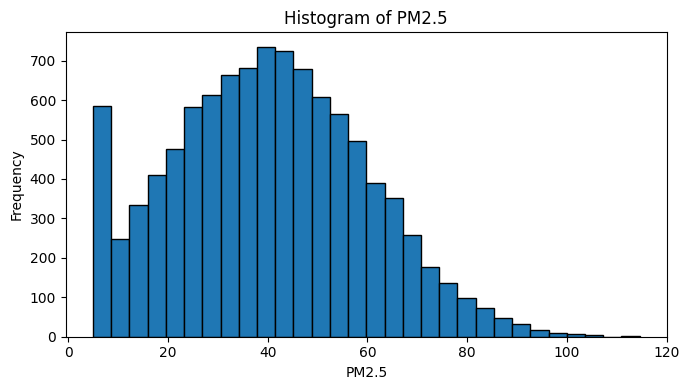

In [38]:
plt.figure(figsize=(7, 4))
plt.hist(data["PM2.5"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of PM2.5")
plt.xlabel("PM2.5")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

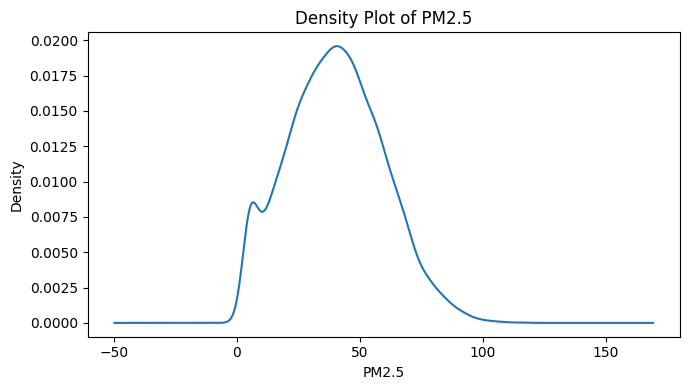

In [39]:
plt.figure(figsize=(7, 4))
data["PM2.5"].dropna().plot(kind="density")
plt.title("Density Plot of PM2.5")
plt.xlabel("PM2.5")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

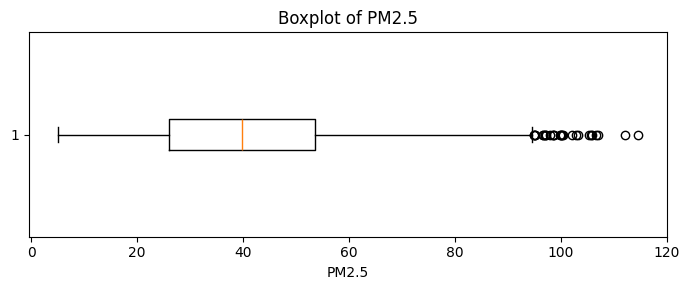

In [40]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["PM2.5"].dropna(), vert=False)
plt.title("Boxplot of PM2.5")
plt.xlabel("PM2.5")
plt.tight_layout()
plt.show()

#### Short interpretation

In [41]:
# show_interpretation("PM2.5")

### PM10

#### Histogram

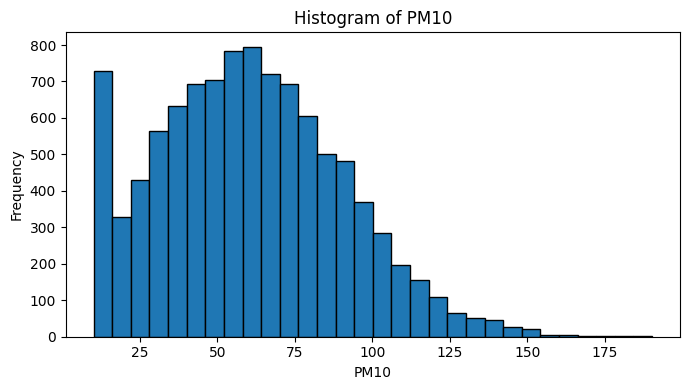

In [42]:
plt.figure(figsize=(7, 4))
plt.hist(data["PM10"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of PM10")
plt.xlabel("PM10")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

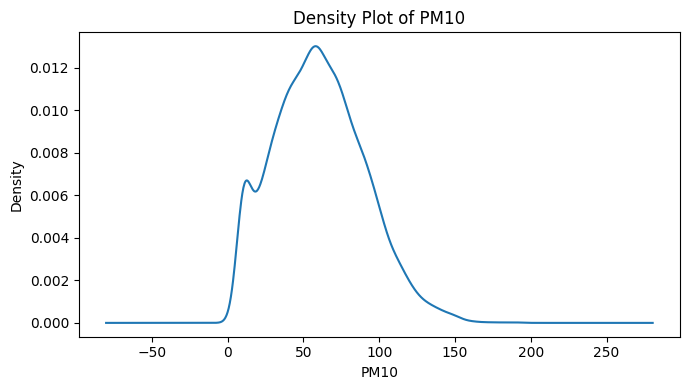

In [43]:
plt.figure(figsize=(7, 4))
data["PM10"].dropna().plot(kind="density")
plt.title("Density Plot of PM10")
plt.xlabel("PM10")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

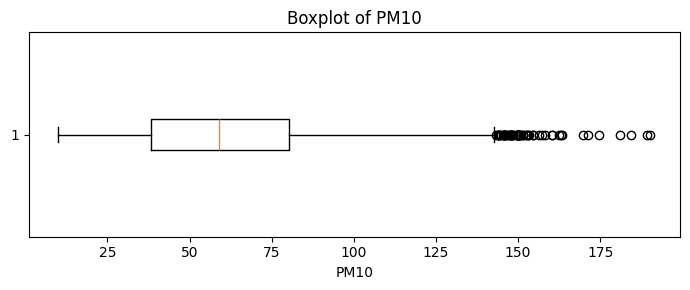

In [44]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["PM10"].dropna(), vert=False)
plt.title("Boxplot of PM10")
plt.xlabel("PM10")
plt.tight_layout()
plt.show()

#### Short interpretation

In [45]:
# show_interpretation("PM10")

### CO

#### Histogram

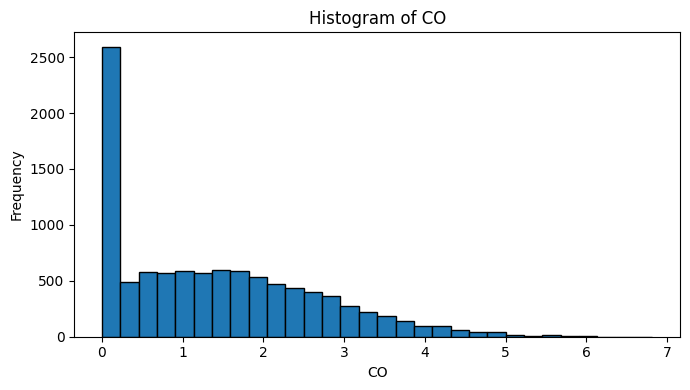

In [46]:
plt.figure(figsize=(7, 4))
plt.hist(data["CO"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of CO")
plt.xlabel("CO")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

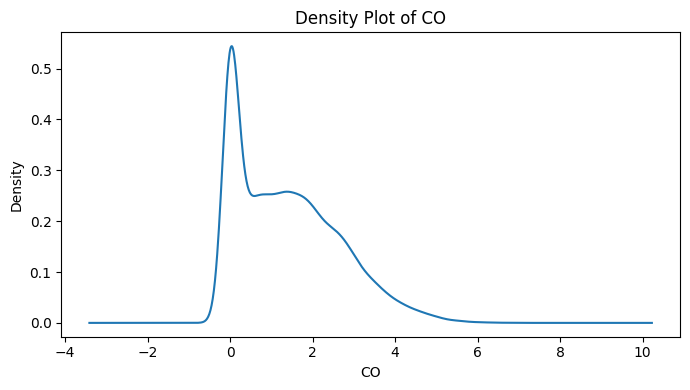

In [47]:
plt.figure(figsize=(7, 4))
data["CO"].dropna().plot(kind="density")
plt.title("Density Plot of CO")
plt.xlabel("CO")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

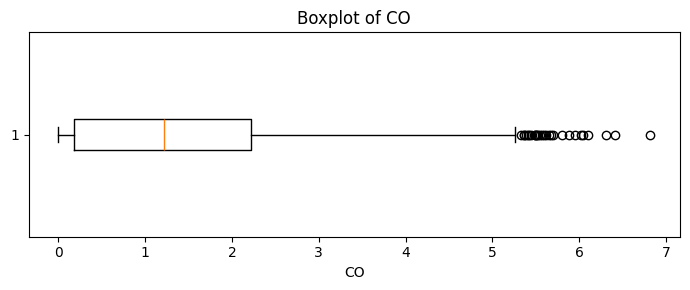

In [48]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["CO"].dropna(), vert=False)
plt.title("Boxplot of CO")
plt.xlabel("CO")
plt.tight_layout()
plt.show()

#### Short interpretation

In [49]:
# show_interpretation("CO")

### NO₂

#### Histogram

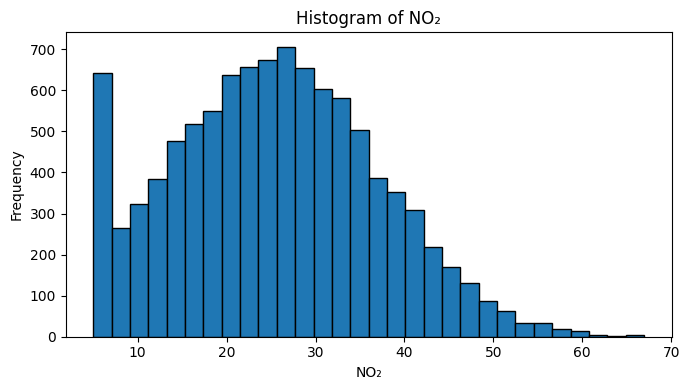

In [50]:
plt.figure(figsize=(7, 4))
plt.hist(data["NO₂"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of NO₂")
plt.xlabel("NO₂")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

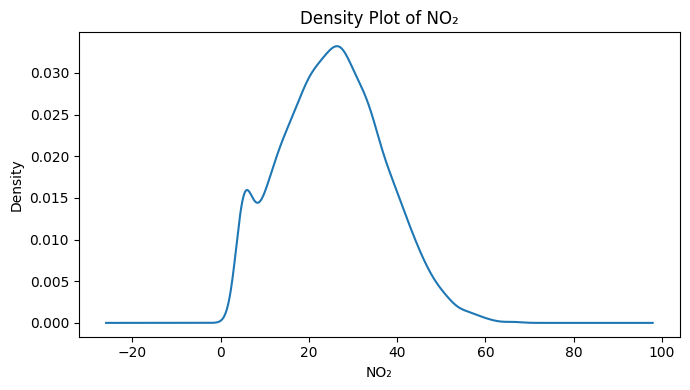

In [51]:
plt.figure(figsize=(7, 4))
data["NO₂"].dropna().plot(kind="density")
plt.title("Density Plot of NO₂")
plt.xlabel("NO₂")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

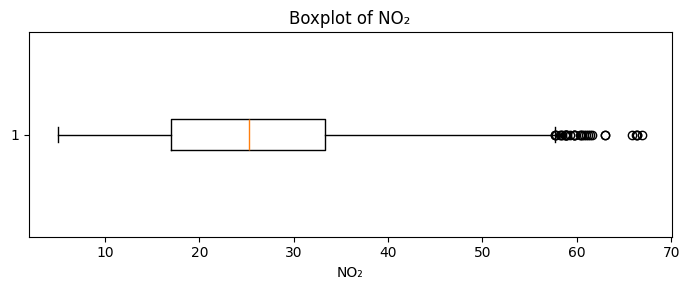

In [52]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["NO₂"].dropna(), vert=False)
plt.title("Boxplot of NO₂")
plt.xlabel("NO₂")
plt.tight_layout()
plt.show()

#### Short interpretation

In [53]:
# show_interpretation("NO₂")

### TVOC

#### Histogram

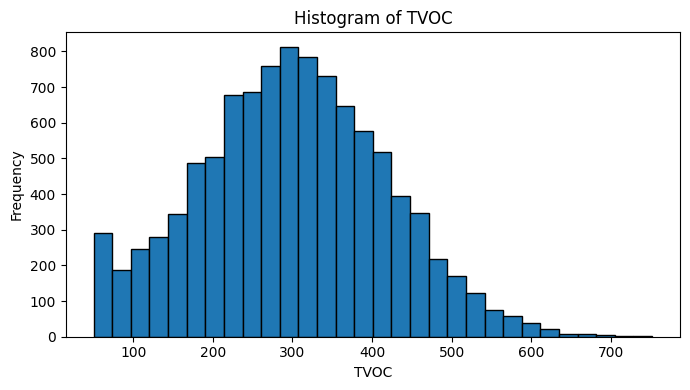

In [54]:
plt.figure(figsize=(7, 4))
plt.hist(data["TVOC"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of TVOC")
plt.xlabel("TVOC")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

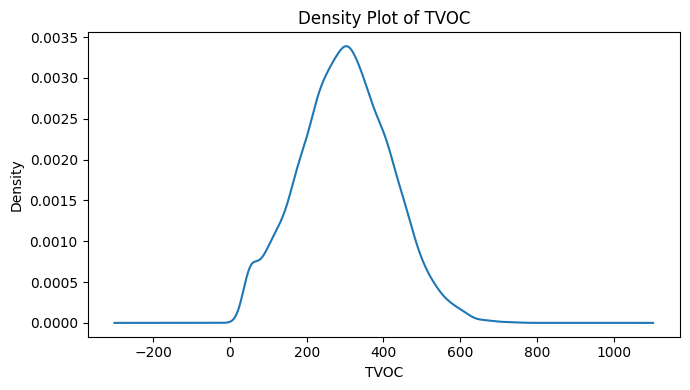

In [55]:
plt.figure(figsize=(7, 4))
data["TVOC"].dropna().plot(kind="density")
plt.title("Density Plot of TVOC")
plt.xlabel("TVOC")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

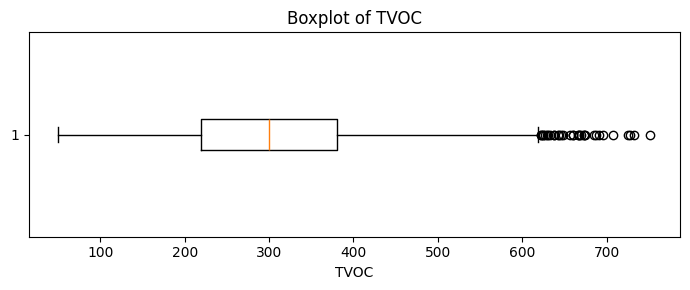

In [56]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["TVOC"].dropna(), vert=False)
plt.title("Boxplot of TVOC")
plt.xlabel("TVOC")
plt.tight_layout()
plt.show()

#### Short interpretation

In [57]:
# show_interpretation("TVOC")

### Indoor Temperature

#### Histogram

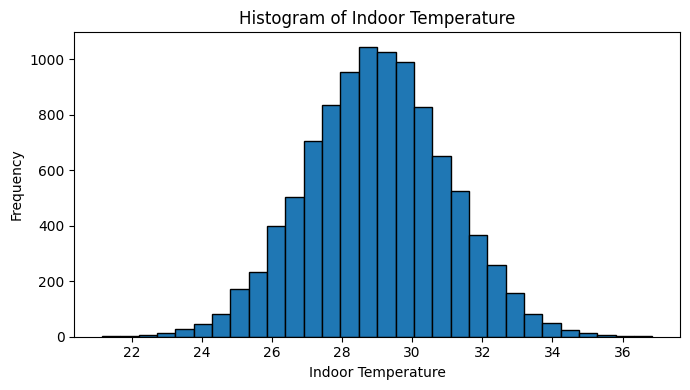

In [58]:
plt.figure(figsize=(7, 4))
plt.hist(data["Indoor Temperature"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of Indoor Temperature")
plt.xlabel("Indoor Temperature")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

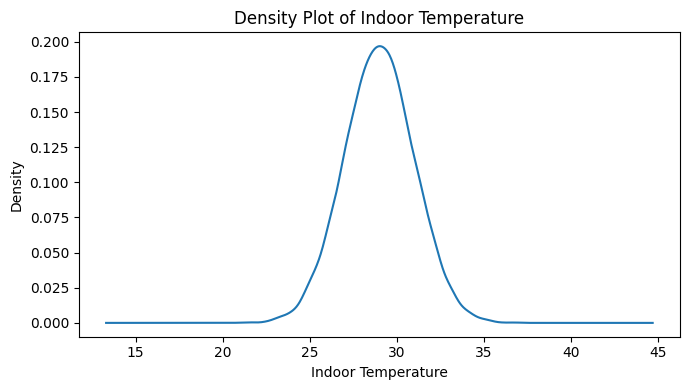

In [59]:
plt.figure(figsize=(7, 4))
data["Indoor Temperature"].dropna().plot(kind="density")
plt.title("Density Plot of Indoor Temperature")
plt.xlabel("Indoor Temperature")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

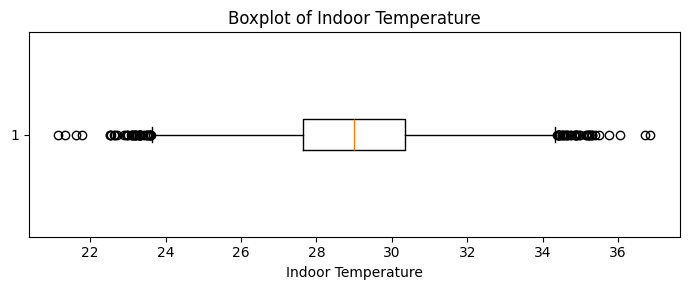

In [60]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["Indoor Temperature"].dropna(), vert=False)
plt.title("Boxplot of Indoor Temperature")
plt.xlabel("Indoor Temperature")
plt.tight_layout()
plt.show()

#### Short interpretation

In [61]:
# show_interpretation("Indoor Temperature")

### Indoor Humidity

#### Histogram

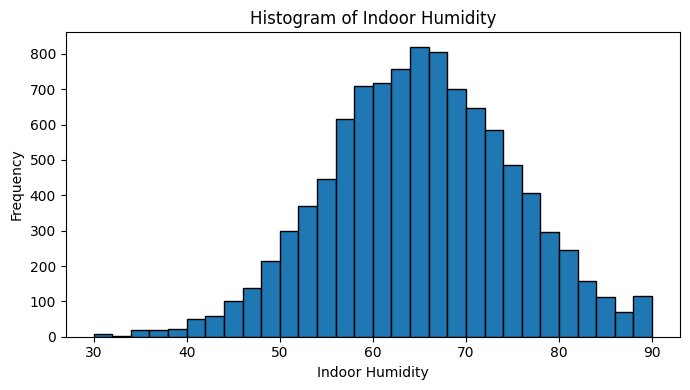

In [62]:
plt.figure(figsize=(7, 4))
plt.hist(data["Indoor Humidity"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of Indoor Humidity")
plt.xlabel("Indoor Humidity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

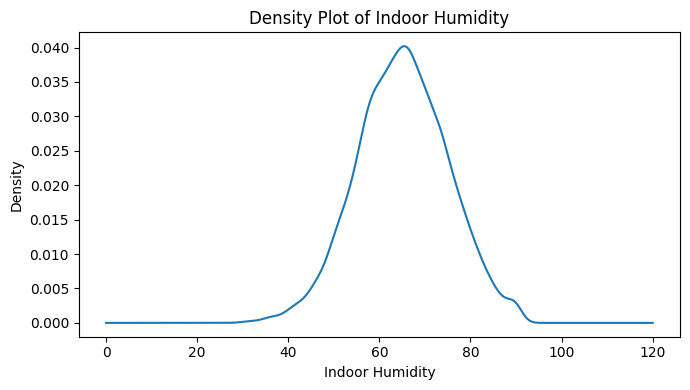

In [63]:
plt.figure(figsize=(7, 4))
data["Indoor Humidity"].dropna().plot(kind="density")
plt.title("Density Plot of Indoor Humidity")
plt.xlabel("Indoor Humidity")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

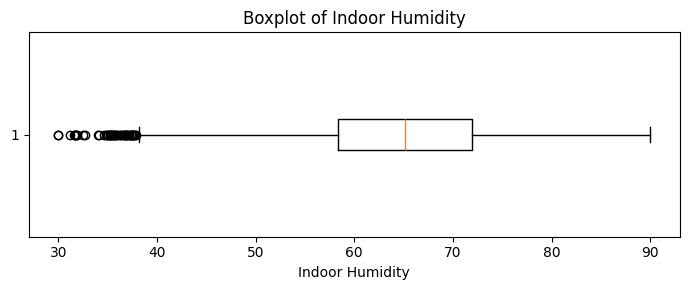

In [64]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["Indoor Humidity"].dropna(), vert=False)
plt.title("Boxplot of Indoor Humidity")
plt.xlabel("Indoor Humidity")
plt.tight_layout()
plt.show()

#### Short interpretation

In [65]:
# show_interpretation("Indoor Humidity")

### Outdoor Temperature

#### Histogram

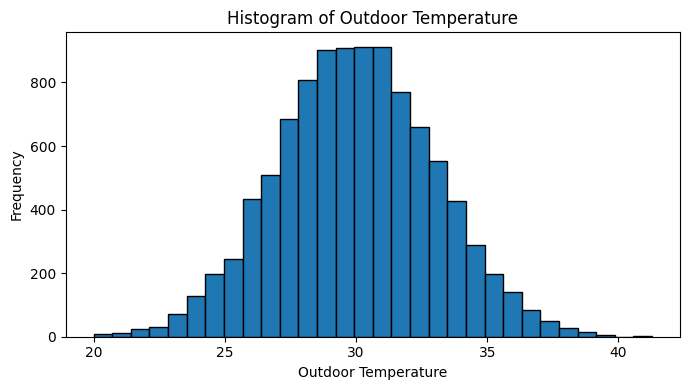

In [66]:
plt.figure(figsize=(7, 4))
plt.hist(data["Outdoor Temperature"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of Outdoor Temperature")
plt.xlabel("Outdoor Temperature")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

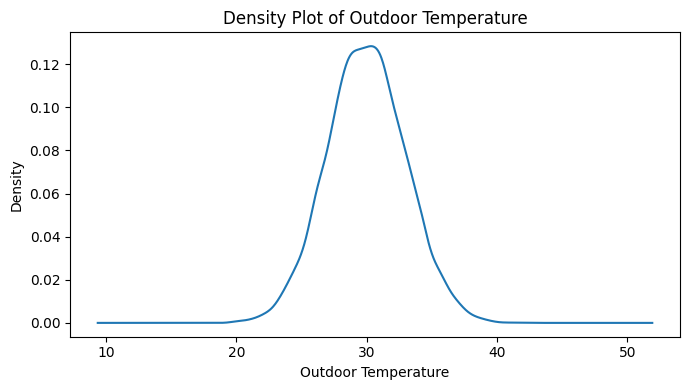

In [67]:
plt.figure(figsize=(7, 4))
data["Outdoor Temperature"].dropna().plot(kind="density")
plt.title("Density Plot of Outdoor Temperature")
plt.xlabel("Outdoor Temperature")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

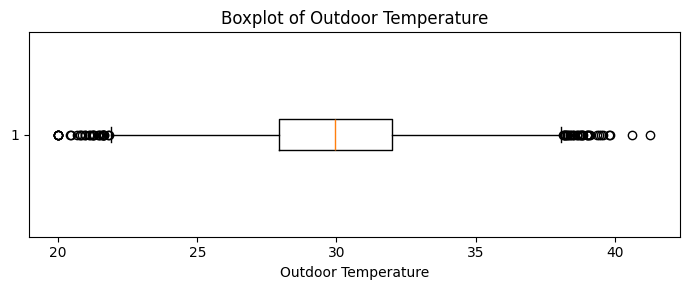

In [68]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["Outdoor Temperature"].dropna(), vert=False)
plt.title("Boxplot of Outdoor Temperature")
plt.xlabel("Outdoor Temperature")
plt.tight_layout()
plt.show()

### Rainfall

#### Histogram

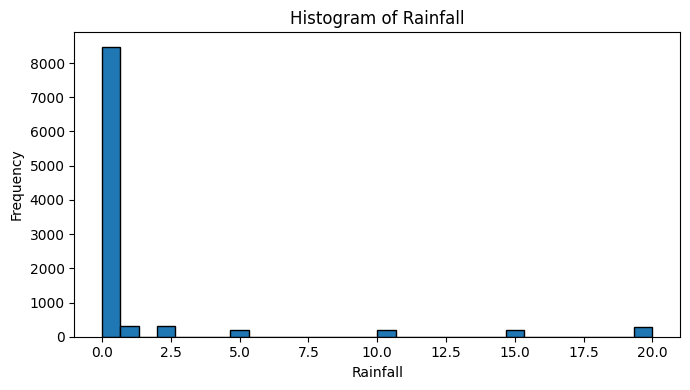

In [69]:
plt.figure(figsize=(7, 4))
plt.hist(data["Rainfall"].dropna(), bins=30, edgecolor="black")
plt.title("Histogram of Rainfall")
plt.xlabel("Rainfall")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Density plot

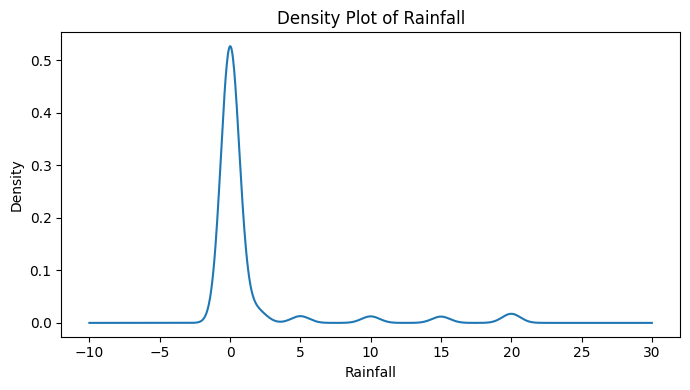

In [70]:
plt.figure(figsize=(7, 4))
data["Rainfall"].dropna().plot(kind="density")
plt.title("Density Plot of Rainfall")
plt.xlabel("Rainfall")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### Boxplot

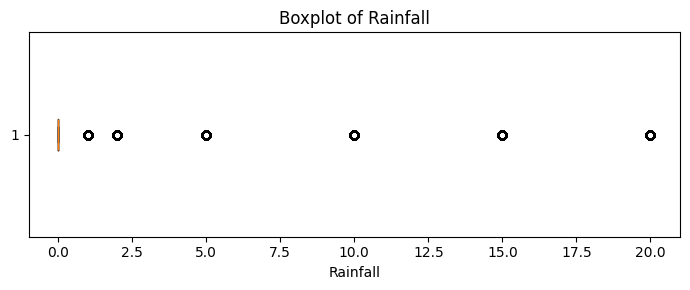

In [71]:
plt.figure(figsize=(7, 3))
plt.boxplot(data["Rainfall"].dropna(), vert=False)
plt.title("Boxplot of Rainfall")
plt.xlabel("Rainfall")
plt.tight_layout()
plt.show()

#### Short interpretation

In [72]:
show_interpretation("Rainfall")

NameError: name 'show_interpretation' is not defined

## 35. Important notes about outliers

- Pollution outliers may represent cooking, smoke, traffic, poor ventilation, or sensor errors.
- Rainfall may have many IQR outliers because Q1 and Q3 can both be zero.
- Outliers should be checked before they are removed.

# Part C: Categorical-Variable Analysis

This part calculates frequency and percentage tables and creates charts for the categorical variables.

## 36. Ventilation Type

### Frequency and percentage table

In [ ]:
ventilation_table = pd.DataFrame({
    "Frequency": df["Ventilation Type"].value_counts(),
    "Percentage": df["Ventilation Type"].value_counts(normalize=True) * 100
})

ventilation_table.round(2)

,Frequency,Percentage
Ventilation Type,,
fan,3976,39.76
exhaust fan,2971,29.71
window open,2015,20.15
window closed,1038,10.38


### Bar chart

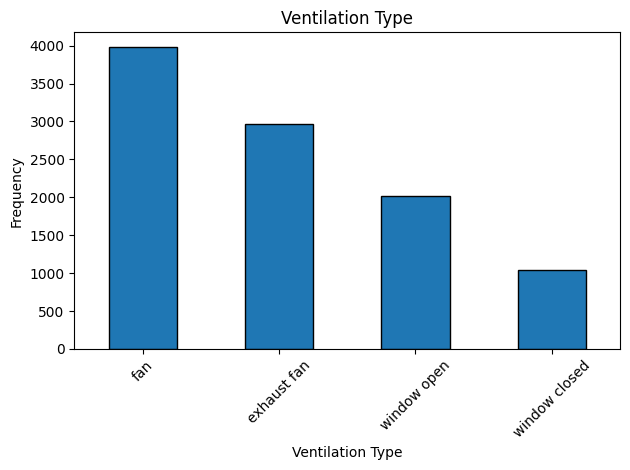

In [ ]:
df["Ventilation Type"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Ventilation Type")
plt.xlabel("Ventilation Type")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 37. Cooking Fuel

### Frequency and percentage table

In [ ]:
cooking_fuel_table = pd.DataFrame({
    "Frequency": df["Cooking Fuel"].value_counts(),
    "Percentage": df["Cooking Fuel"].value_counts(normalize=True) * 100
})

cooking_fuel_table.round(2)

,Frequency,Percentage
Cooking Fuel,,
gas,7481,74.81
electric,1518,15.18
induction,1001,10.01


### Bar chart

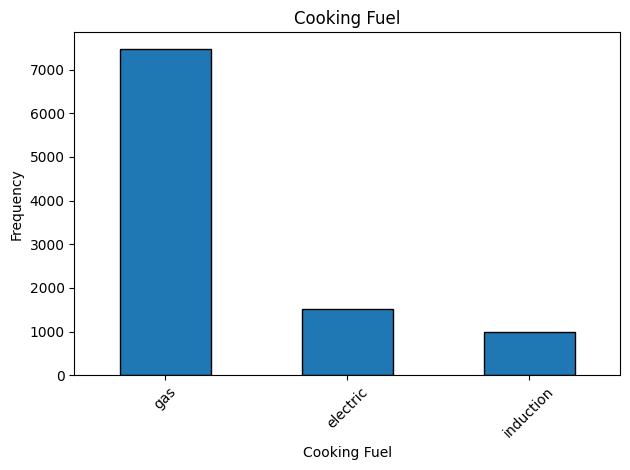

In [ ]:
df["Cooking Fuel"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Cooking Fuel")
plt.xlabel("Cooking Fuel")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 38. Nearby Traffic

### Frequency and percentage table

In [ ]:
nearby_traffic_table = pd.DataFrame({
    "Frequency": df["Nearby Traffic"].value_counts(),
    "Percentage": df["Nearby Traffic"].value_counts(normalize=True) * 100
})

nearby_traffic_table.round(2)

,Frequency,Percentage
Nearby Traffic,,
low,4937,49.37
medium,3540,35.40
high,1523,15.23


### Bar chart

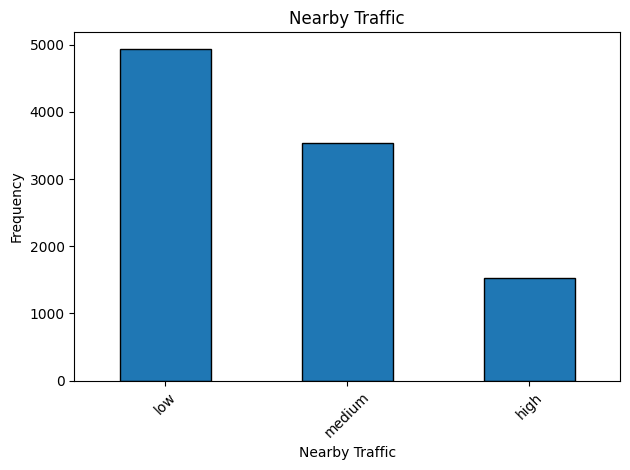

In [ ]:
df["Nearby Traffic"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Nearby Traffic")
plt.xlabel("Nearby Traffic")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 39. Floor Level

### Frequency and percentage table

In [ ]:
floor_level_table = pd.DataFrame({
    "Frequency": df["Floor Level"].value_counts(),
    "Percentage": df["Floor Level"].value_counts(normalize=True) * 100
})

floor_level_table.round(2)

,Frequency,Percentage
Floor Level,,
1st,4050,40.50
2nd,2966,29.66
3rd,2015,20.15
top,969,9.69


### Bar chart

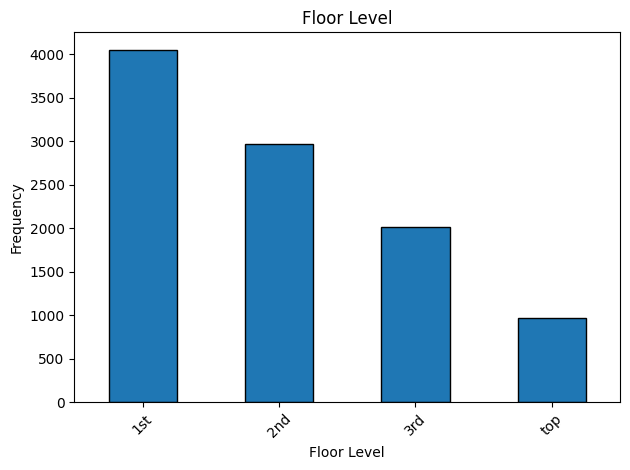

In [ ]:
df["Floor Level"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Floor Level")
plt.xlabel("Floor Level")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Pie chart

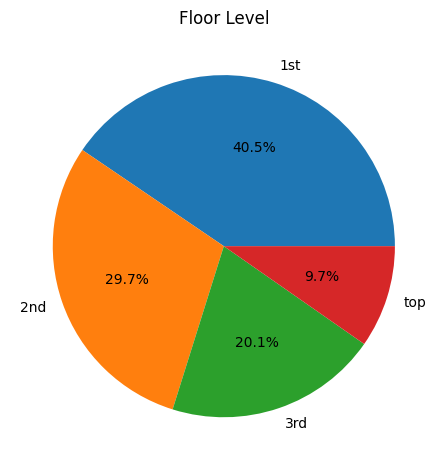

In [ ]:
df["Floor Level"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Floor Level")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 40. Time of Day

### Frequency and percentage table

In [ ]:
time_of_day_table = pd.DataFrame({
    "Frequency": df["Time of Day"].value_counts(),
    "Percentage": df["Time of Day"].value_counts(normalize=True) * 100
})

time_of_day_table.round(2)

,Frequency,Percentage
Time of Day,,
night,3328,33.28
morning,2928,29.28
afternoon,2080,20.80
evening,1664,16.64


### Bar chart

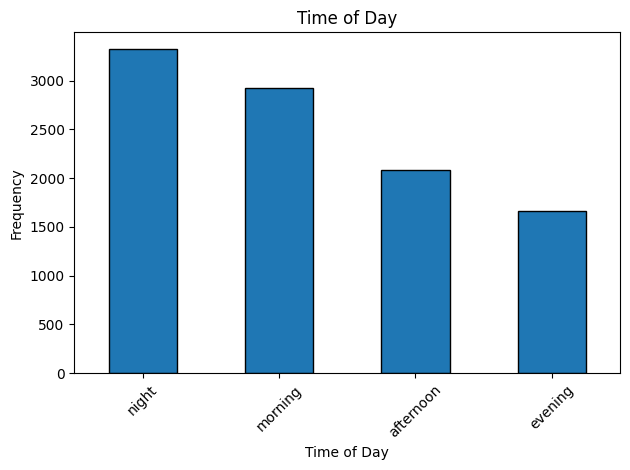

In [ ]:
df["Time of Day"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Pie chart

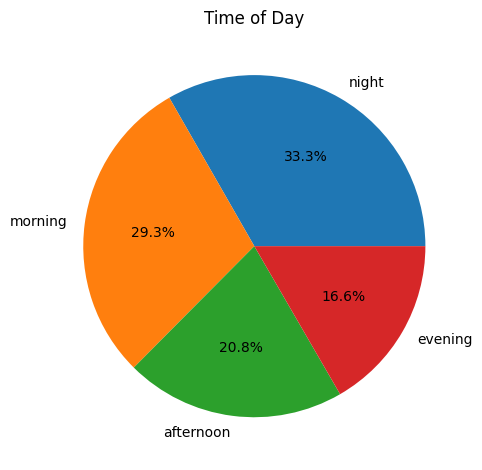

In [ ]:
df["Time of Day"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Time of Day")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 41. Season

### Frequency and percentage table

In [ ]:
season_table = pd.DataFrame({
    "Frequency": df["Season"].value_counts(),
    "Percentage": df["Season"].value_counts(normalize=True) * 100
})

season_table.round(2)

,Frequency,Percentage
Season,,
winter,5736,57.36
summer,4264,42.64


### Bar chart

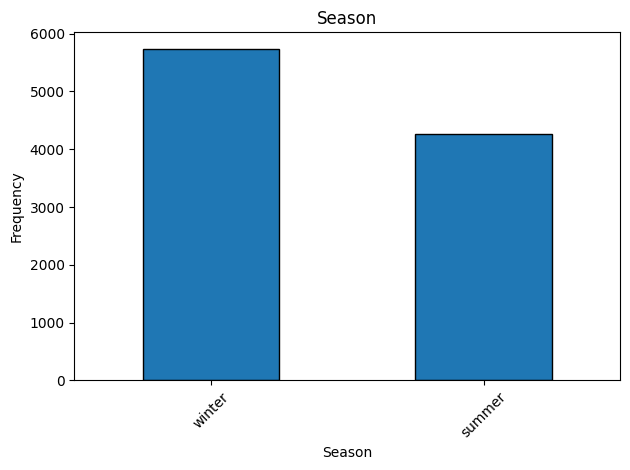

In [ ]:
df["Season"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Season")
plt.xlabel("Season")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 42. Short interpretation of categorical variables

- Frequency shows the number of observations in each category.
- Percentage shows the share of each category.
- Bar and pie charts make the most common categories easier to identify.

# Part D: Relationships Between Variables

Scatter plots are used to examine the relationships between selected numerical variables.

## 43. PM2.5 and PM10

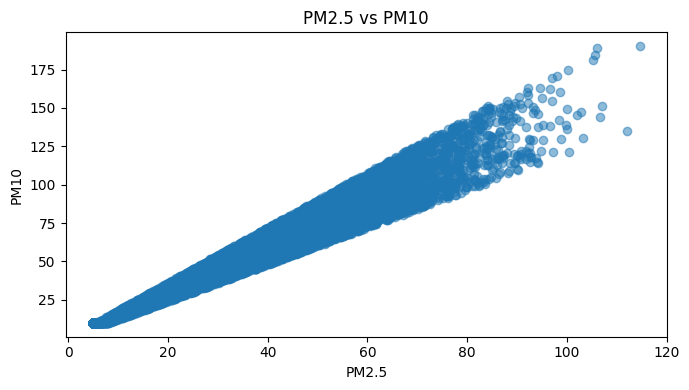

Correlation: 0.966


In [ ]:
x = df["PM2.5 (µg/m³)"]
y = df["PM10 (µg/m³)"]

plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.5)
plt.xlabel("PM2.5")
plt.ylabel("PM10")
plt.title("PM2.5 vs PM10")
plt.tight_layout()
plt.show()

print("Correlation:", round(x.corr(y), 3))

## 44. Occupancy and CO₂

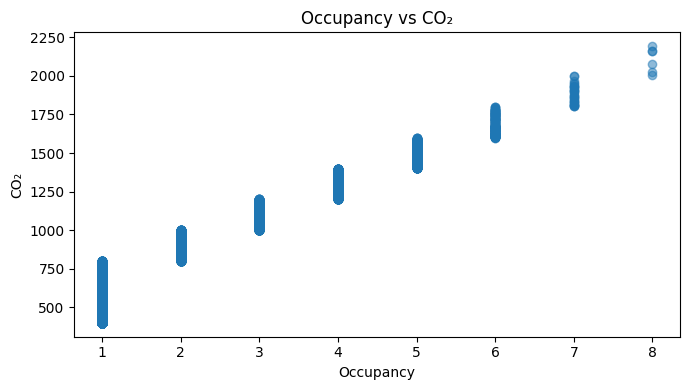

Correlation: 0.949


In [ ]:
x = df["Occupancy (people)"]
y = df["CO2 (ppm)"]

plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.5)
plt.xlabel("Occupancy")
plt.ylabel("CO₂")
plt.title("Occupancy vs CO₂")
plt.tight_layout()
plt.show()

print("Correlation:", round(x.corr(y), 3))

## 45. Household Size and CO₂

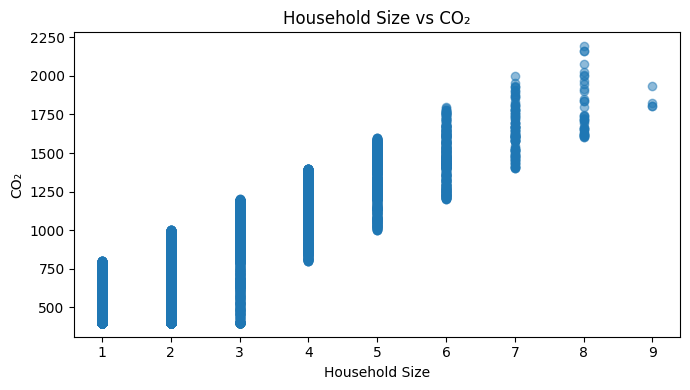

Correlation: 0.849


In [ ]:
x = df["Household Size"]
y = df["CO2 (ppm)"]

plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.5)
plt.xlabel("Household Size")
plt.ylabel("CO₂")
plt.title("Household Size vs CO₂")
plt.tight_layout()
plt.show()

print("Correlation:", round(x.corr(y), 3))

## 46. Household Size and Occupancy

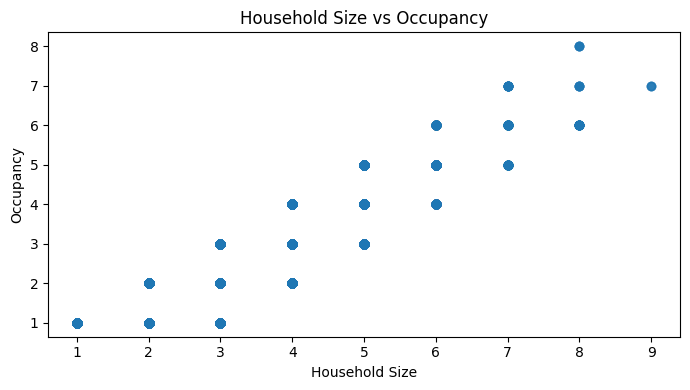

Correlation: 0.895


In [ ]:
x = df["Household Size"]
y = df["Occupancy (people)"]

plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.5)
plt.xlabel("Household Size")
plt.ylabel("Occupancy")
plt.title("Household Size vs Occupancy")
plt.tight_layout()
plt.show()

print("Correlation:", round(x.corr(y), 3))

## 47. Outdoor and Indoor Temperature

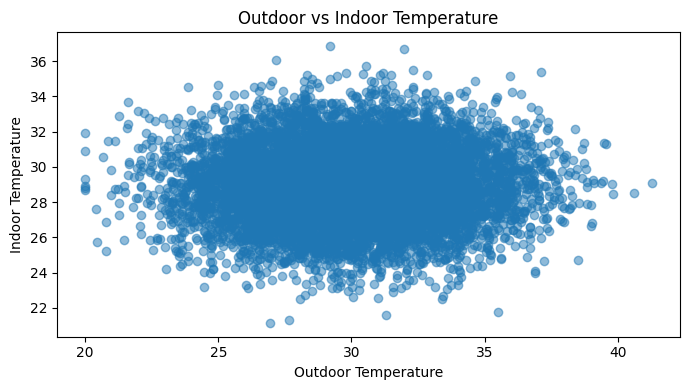

Correlation: 0.017


In [ ]:
x = df["Outdoor Temperature (°C)"]
y = df["Indoor Temperature (°C)"]

plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.5)
plt.xlabel("Outdoor Temperature")
plt.ylabel("Indoor Temperature")
plt.title("Outdoor vs Indoor Temperature")
plt.tight_layout()
plt.show()

print("Correlation:", round(x.corr(y), 3))

## 48. Occupancy and TVOC

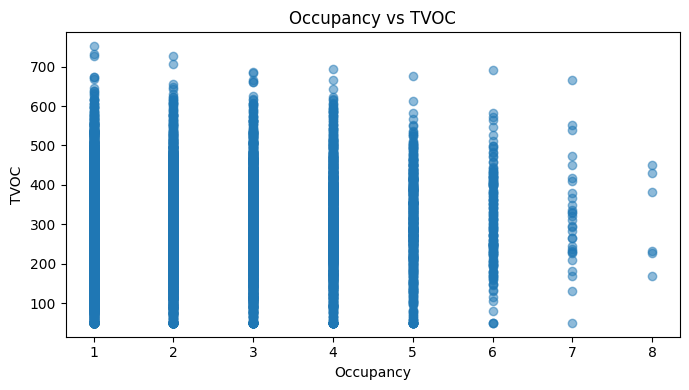

Correlation: 0.017


In [ ]:
x = df["Occupancy (people)"]
y = df["TVOC (ppb)"]

plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.5)
plt.xlabel("Occupancy")
plt.ylabel("TVOC")
plt.title("Occupancy vs TVOC")
plt.tight_layout()
plt.show()

print("Correlation:", round(x.corr(y), 3))

## 49. Cooking Frequency and PM2.5

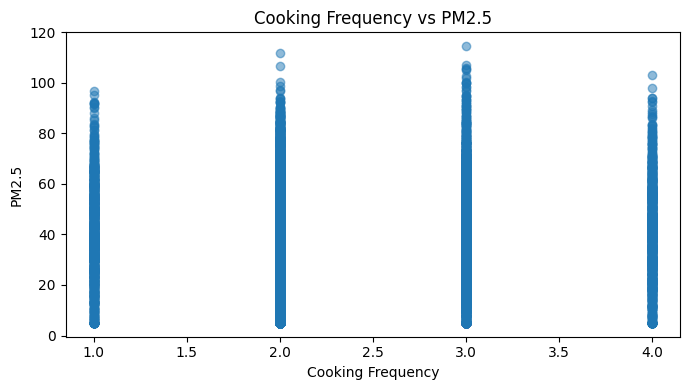

Correlation: 0.003


In [ ]:
x = df["Cooking Frequency (per day)"]
y = df["PM2.5 (µg/m³)"]

plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.5)
plt.xlabel("Cooking Frequency")
plt.ylabel("PM2.5")
plt.title("Cooking Frequency vs PM2.5")
plt.tight_layout()
plt.show()

print("Correlation:", round(x.corr(y), 3))

## 50. Short interpretation of relationships

- An upward pattern suggests a positive relationship.
- A downward pattern suggests a negative relationship.
- A scattered pattern suggests a weak relationship.
- Correlation describes association, not causation.

# Part E: Save the Main Result Tables

## 51. Save the descriptive-statistics table

In [ ]:
descriptive_summary.round(2).to_csv(
    "descriptive_statistics_summary.csv",
    index=True
)

print("Descriptive-statistics table saved.")

Descriptive-statistics table saved.


## 52. Save the distribution and outlier table

In [ ]:
distribution_summary.round(2).to_csv(
    "distribution_and_outlier_summary.csv",
    index=True
)

print("Distribution and outlier table saved.")

Distribution and outlier table saved.


In [80]:
# Import required libraries for Linear Regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

In [81]:


linear_data = df[["Occupancy (people)", "CO2 (ppm)"]].copy()
# linear_data = linear_data.replace([np.inf, -np.inf], np.nan).dropna()

#input column
X = linear_data[["Occupancy (people)"]]

# output column
y = linear_data["CO2 (ppm)"]

print("Usable rows for Linear Regression:", len(linear_data))

Usable rows for Linear Regression: 10000


In [82]:
# Split the data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 8000
Testing rows: 2000


In [83]:
# train the Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict CO2 values for the test data
y_pred = linear_model.predict(X_test)

In [84]:
# Calculate the required evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))

Mean Squared Error (MSE): 10835.84
Root Mean Squared Error (RMSE): 104.1


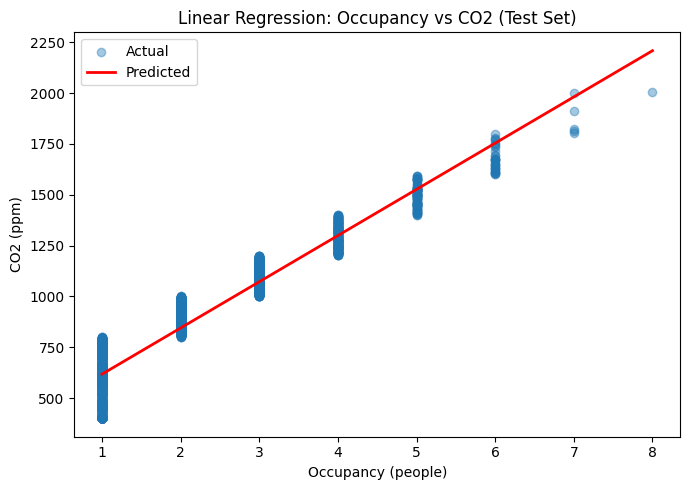

In [85]:
# Visualize the regression fit
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, alpha=0.4, label="Actual")
order = np.argsort(X_test["Occupancy (people)"].values)
plt.plot(X_test["Occupancy (people)"].values[order], y_pred[order],
         color="red", linewidth=2, label="Predicted")
plt.xlabel("Occupancy (people)")
plt.ylabel("CO2 (ppm)")
plt.title("Linear Regression: Occupancy vs CO2 (Test Set)")
plt.legend()
plt.tight_layout()
plt.show()

In [92]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

In [ ]:

# PM10 is split into "High" and "Low" using the median value
pm10_median = df["PM10 (µg/m³)"].median()

clf_columns = ["PM2.5 (µg/m³)", "NO2 (ppb)", "CO (ppm)", "TVOC (ppb)", "PM10 (µg/m³)"]
clf_data = df[clf_columns].replace([np.inf, -np.inf], np.nan).dropna()

clf_data["PM10 Level"] = np.where(
    clf_data["PM10 (µg/m³)"] > pm10_median, "High", "Low"
)


X_clf = clf_data[["PM2.5 (µg/m³)", "NO2 (ppb)", "CO (ppm)", "TVOC (ppb)"]] #input
y_clf = clf_data["PM10 Level"] #output

print("Usable rows for Logistic Regression:", len(clf_data))
print(y_clf.value_counts())

Usable rows for Logistic Regression: 10000
PM10 Level
Low     5000
High    5000
Name: count, dtype: int64


In [94]:
# Split the data into 80% training and 20% testing sets
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

# Scale the features (Logistic Regression performs better with scaled data)
scaler = StandardScaler()
X_train_clf_scaled = scaler.fit_transform(X_train_clf)
X_test_clf_scaled = scaler.transform(X_test_clf)

print("Training rows:", len(X_train_clf))
print("Testing rows:", len(X_test_clf))

Training rows: 8000
Testing rows: 2000


In [95]:
# Create and train the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_clf_scaled, y_train_clf)

# Predict PM10 Level for the test data
y_pred_clf = logistic_model.predict(X_test_clf_scaled)

In [96]:
# Calculate the required evaluation metrics
accuracy = accuracy_score(y_test_clf, y_pred_clf)
f1 = f1_score(y_test_clf, y_pred_clf, average="weighted")

print("Accuracy:", round(accuracy, 4))
print("F1 Score (weighted):", round(f1, 4))
print()
print(classification_report(y_test_clf, y_pred_clf))

Accuracy: 0.922
F1 Score (weighted): 0.922

              precision    recall  f1-score   support

        High       0.93      0.92      0.92      1000
         Low       0.92      0.93      0.92      1000

    accuracy                           0.92      2000
   macro avg       0.92      0.92      0.92      2000
weighted avg       0.92      0.92      0.92      2000



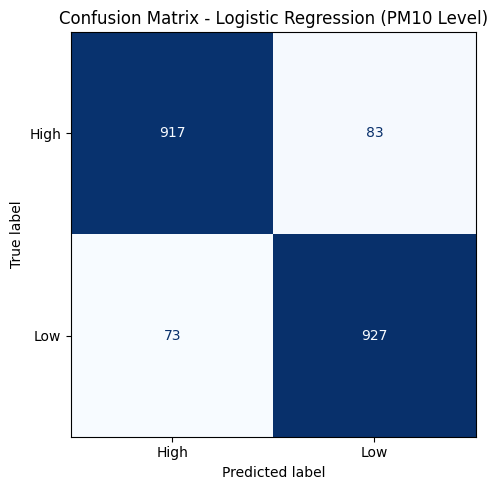

In [97]:
# Visualize the confusion matrix
cm = confusion_matrix(y_test_clf, y_pred_clf, labels=logistic_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logistic_model.classes_)

fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - Logistic Regression (PM10 Level)")
plt.tight_layout()
plt.show()